# 08 · Ba mô hình ML, huấn luyện trên bảng Hive

- Yield: 30 quốc gia × 15 năm = 450 mẫu, chia theo thời gian.
- Anomaly: Isolation Forest trên 1.052.064 dòng hourly.
- Forecast: 7 ngày cho 3 địa điểm, so với persistence.

In [1]:
import json
import subprocess
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ART = ROOT / "artifacts"
REPORTS = ROOT / "reports"

def sh(command, timeout=600):
    result = subprocess.run(command, capture_output=True, text=True, timeout=timeout)
    return result.stdout + result.stderr

def read_json(path):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else {}

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
GREEN, TEAL, GOLD, RED = "#1F6B45", "#2B6E7A", "#8F5E1A", "#A23B2A"

## 1. Yield model

In [2]:
metrics = read_json(ART / "ml" / "yield_metrics.json")
print("Best model:", metrics.get("best_model"), "| test rows:", metrics.get("test_rows"))
rows = []
for name, payload in metrics.get("comparison", {}).items():
    rows.append({"model": name, "validation_MAE": payload["validation"]["mae"]})
rows.append({"model": metrics.get("best_model", "") + " (test)", "validation_MAE": metrics.get("test", {}).get("mae")})
display(pd.DataFrame(rows))
print("Test R2:", metrics.get("test", {}).get("r2"), "| MAPE:", metrics.get("test", {}).get("mape_pct"), "%")
print("Baseline MAE:", metrics.get("baseline_test", {}).get("mae"), "| cải thiện:", metrics.get("mae_improvement_pct"), "%")

Best model: random_forest | test rows: 60


,model,validation_MAE
0,baseline_mean,1355.360
1,gradient_boosting,621.851
2,random_forest,497.042
3,ridge,1072.923
4,random_forest (test),416.848


Test R2: 0.9088 | MAPE: 10.648 %
Baseline MAE: 1432.359 | cải thiện: 70.9 %


## 2. Dự đoán so với thực tế

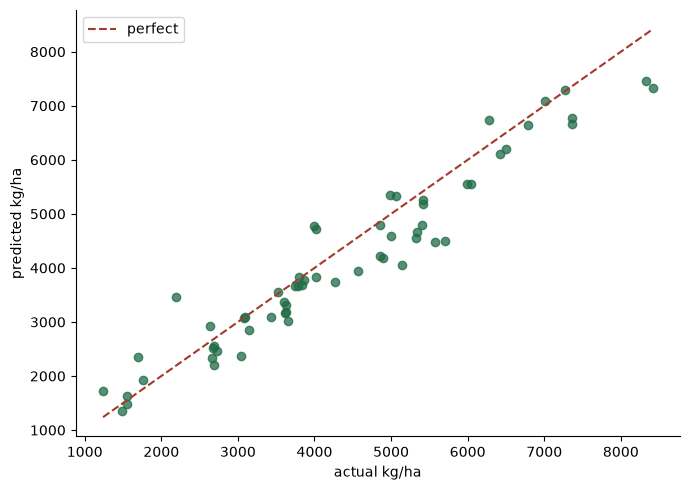

In [3]:
pred = pd.read_csv(ART / "ml" / "yield_predictions.csv")
test = pred[pred["split"] == "test"]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(test["actual_kg_ha"], test["predicted_kg_ha"], color=GREEN, alpha=0.75)
limit = [test["actual_kg_ha"].min(), test["actual_kg_ha"].max()]
ax.plot(limit, limit, color=RED, linestyle="--", label="perfect")
ax.set_xlabel("actual kg/ha"); ax.set_ylabel("predicted kg/ha"); ax.legend()
plt.tight_layout(); plt.show()

## 3. Feature importance

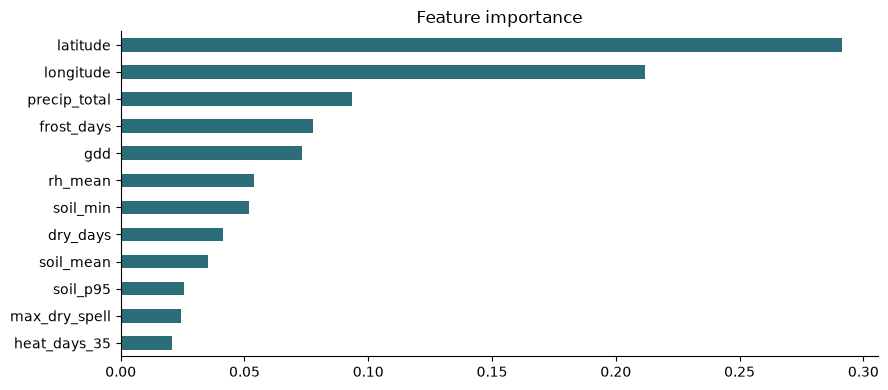

Cảnh báo: latitude/longitude chiếm ưu thế, model học khác biệt vùng/quốc gia,
không phải quan hệ nhân quả khí hậu → năng suất.


In [4]:
importance = pd.Series(metrics.get("feature_importance", {})).sort_values()
if len(importance):
    importance.plot.barh(color=TEAL)
    plt.title("Feature importance")
    plt.tight_layout(); plt.show()
    print("Cảnh báo: latitude/longitude chiếm ưu thế, model học khác biệt vùng/quốc gia,")
    print("không phải quan hệ nhân quả khí hậu → năng suất.")

## 4. Anomaly detection

In [5]:
anomaly = read_json(ART / "ml" / "anomaly_metrics.json")
print(json.dumps({k: anomaly.get(k) for k in ("rows_scored", "flagged", "flagged_pct", "event_caught", "event_rank", "event_top_pct", "zscore_flagged")}, indent=2))
if (ART / "ml" / "ml_anomalies.csv").exists():
    display(pd.read_csv(ART / "ml" / "ml_anomalies.csv").head(10))

{
  "rows_scored": 1052064,
  "flagged": 5441,
  "flagged_pct": 0.5172,
  "event_caught": true,
  "event_rank": 20,
  "event_top_pct": 0.0019,
  "zscore_flagged": 37
}


,event_time,location_id,t2m_c,rh2m_pct,precip_mm_h,ws2m_ms,soil_wetness_root,score,z_precip,rank
0,2024-09-07 11:00:00,VN-HD,27.75,87.19,12.90,12.36,0.91,-0.231078,4.958041,1
1,2019-07-12 07:00:00,IN-PB,32.85,57.73,22.49,1.17,0.41,-0.230150,11.245000,2
2,2024-09-07 10:00:00,VN-HD,27.16,86.95,12.63,12.34,0.90,-0.229807,4.854107,3
3,2023-08-05 14:00:00,IN-PB,33.03,71.75,29.31,1.93,0.84,-0.221198,14.655000,4
4,2023-08-05 13:00:00,IN-PB,33.18,70.99,27.66,1.76,0.83,-0.220228,13.830000,5
5,2020-10-18 14:00:00,VN-HD,22.47,85.19,28.80,4.02,0.92,-0.218058,11.078605,6
6,2024-09-07 12:00:00,VN-HD,28.33,87.62,10.75,11.97,0.91,-0.217618,4.130418,7
7,2023-08-05 09:00:00,IN-PB,31.07,76.58,30.42,1.42,0.79,-0.216286,15.210000,8
8,2016-06-28 07:00:00,IN-PB,34.38,54.63,17.52,0.87,0.40,-0.216100,8.760000,9
9,2020-10-18 13:00:00,VN-HD,22.29,83.40,36.27,4.45,0.91,-0.215234,13.954115,10


## 5. Forecast 7 ngày

In [6]:
forecast = read_json(ART / "ml" / "forecast_metrics.json")
rows = []
for location, methods in forecast.get("locations", {}).items():
    rows.append({
        "location": location,
        "ridge_MAE": methods["ridge"]["mae"],
        "sarimax_MAE": methods["sarimax"]["mae"],
        "persistence_MAE": methods["persistence"]["mae"],
        "best": forecast.get("best_by_location", {}).get(location),
    })
display(pd.DataFrame(rows))
print("SARIMAX thắng persistence ở:", forecast.get("sarimax_beats_persistence"))

,location,ridge_MAE,sarimax_MAE,persistence_MAE,best
0,FR-CVL,0.01852,0.01018,0.00999,persistence
1,US-IA,0.02270,0.01204,0.01164,persistence
2,VN-CT,0.01965,0.01450,0.01447,persistence


SARIMAX thắng persistence ở: []


## Đọc kết quả cho đúng

- Yield tốt hơn baseline rất nhiều, nhưng 60 mẫu test và đặc trưng toạ độ chiếm ưu thế: đây là
  mô hình học vùng, không phải mô hình nông học nhân quả.
- Anomaly bắt đúng sự kiện Cần Thơ 14/06/2020, hạng 20 trong 1.052.064 dòng (top 0.002%).
- Forecast: persistence vẫn là baseline mạnh nhất ở cả 3 địa điểm. SARIMAX tiến sát nhưng chưa thắng.
  Notebook giữ nguyên kết quả, không chọn test cho đẹp.